# Input-gradient sensitivity and FGSM

How quickly does a trained classifier lose accuracy under a bounded input perturbation?

I compare random noise with a one-step gradient attack at predefined magnitudes. The model is frozen after ordinary validation; attack results describe sensitivity on its test images.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    Trainer,
    TrainConfig,
    classification_scores,
    digits_data,
    image_grid,
    plot_history,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "12_adversarial_sensitivity"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Data and split

The 1,797 handwritten digit images come from `sklearn.datasets.load_digits`. Intensities are divided by the known sensor maximum of 16. The original 8 by 8 images are resized to 16 by 16 for the convolutional experiments. Resizing adds no measured detail. The split is stratified: 60% train, 20% validation and 20% test.

{'train': 1077, 'validation': 360, 'test': 360}


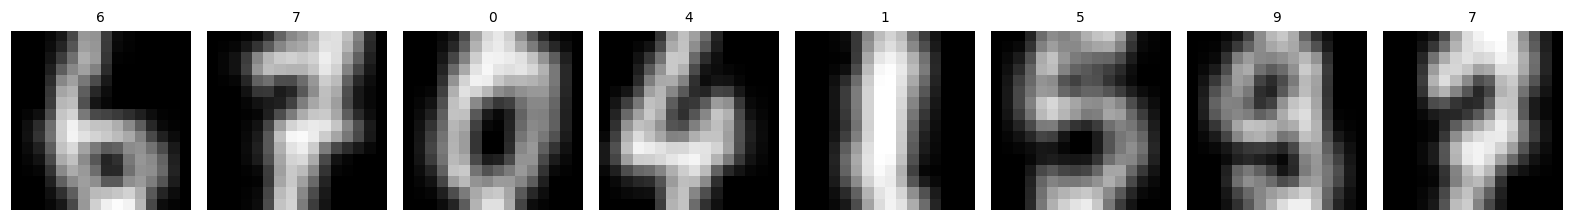

In [5]:
from vision_projects.models import LeNet

data = digits_data()
train_loader, validation_loader, test_loader = data.loaders()
train_images, train_labels = data.train.tensors
print(
    {
        "train": len(data.train),
        "validation": len(data.validation),
        "test": len(data.test),
    }
)
image_grid(train_images[:8], output / "examples.png", train_labels[:8].tolist())

## Train the reference classifier

The reference network uses ordinary cross-entropy training. The attack is an evaluation after checkpoint selection, so it does not enter model training or validation decisions.

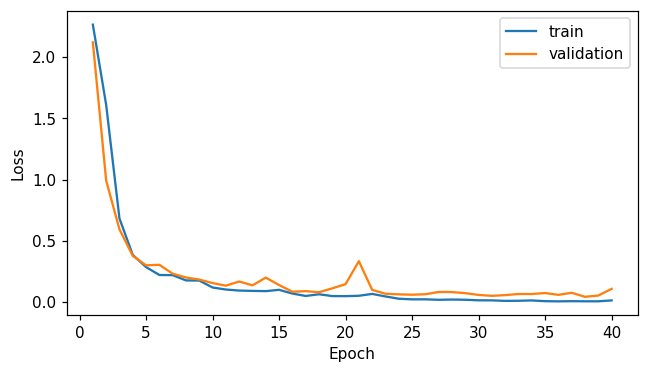

{'accuracy': 0.975, 'macro_f1': 0.9747890386926619, 'nll': 0.10337983119860333}


In [7]:
model = LeNet()
history = Trainer(model, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS)).fit(
    train_loader, validation_loader
)
plot_history(history, output / "loss.png")
model.eval()
clean_images, targets = data.test.tensors
clean_logits = model(clean_images).detach()
clean_correct = clean_logits.argmax(-1) == targets
print(classification_scores(clean_logits, targets))

## Input gradients

FGSM moves the image in the sign direction of the loss gradient: $x'=\mathrm{clip}(x+\epsilon\operatorname{sign}\nabla_x\ell,0,1)$. The attack uses labels to evaluate a white-box worst-case direction. It is not a label-free deployment procedure.

In [9]:
images = clean_images.clone().requires_grad_(True)
attack_loss = F.cross_entropy(model(images), targets)
(gradient,) = torch.autograd.grad(attack_loss, images)
assert torch.isfinite(gradient).all()
rows, adversarial_examples = [], {}
rng = torch.Generator().manual_seed(1031)
random_direction = torch.empty_like(clean_images).uniform_(-1, 1, generator=rng).sign()
for epsilon in [0.0, 0.03, 0.06, 0.12, 0.2]:
    for kind, direction in [("random", random_direction), ("fgsm", gradient.sign())]:
        perturbed = (clean_images + epsilon * direction).clamp(0, 1)
        assert (perturbed - clean_images).abs().max() <= epsilon + 1e-6
        with torch.inference_mode():
            logits = model(perturbed)
        predictions = logits.argmax(-1)
        attack_success = float(
            (predictions[clean_correct] != targets[clean_correct]).float().mean()
        )
        rows.append(
            {
                "kind": kind,
                "epsilon": epsilon,
                "accuracy": float((predictions == targets).float().mean()),
                "success_on_clean_correct": attack_success,
            }
        )
        adversarial_examples[(kind, epsilon)] = perturbed
print(pd.DataFrame(rows))

     kind  epsilon  accuracy  success_on_clean_correct
0  random     0.00  0.975000                  0.000000
1    fgsm     0.00  0.975000                  0.000000
2  random     0.03  0.972222                  0.002849
3    fgsm     0.03  0.847222                  0.131054
4  random     0.06  0.975000                  0.005698
5    fgsm     0.06  0.480556                  0.507123
6  random     0.12  0.961111                  0.022792
7    fgsm     0.12  0.133333                  0.863248
8  random     0.20  0.927778                  0.056980
9    fgsm     0.20  0.047222                  0.951567


## Perturbation curve

Attack success is conditional on images that were classified correctly before perturbation. Overall accuracy includes originally incorrect images too. Both are useful, but their denominators answer different questions.

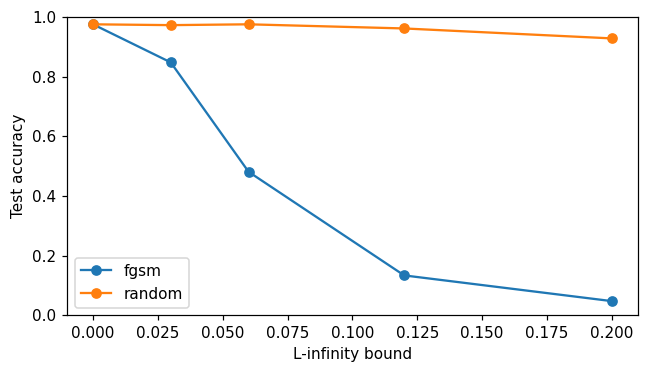

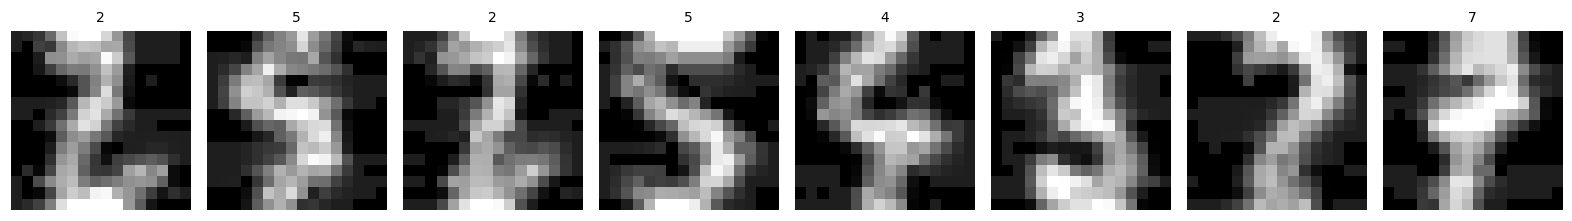

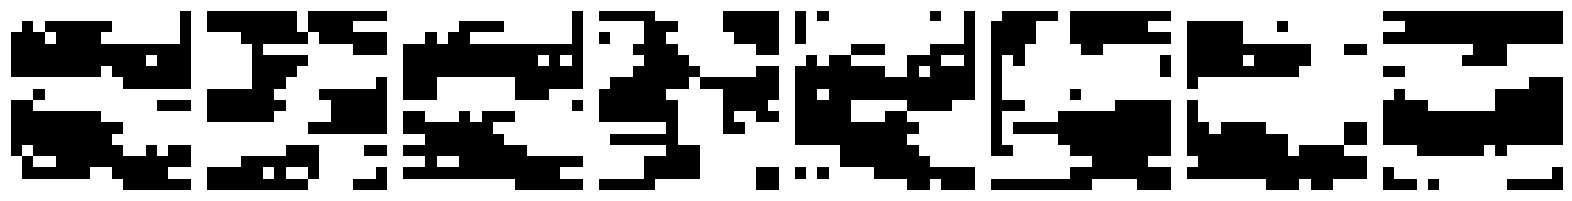

In [11]:
frame = pd.DataFrame(rows)
fig, axis = plt.subplots(figsize=(6, 3.5))
for kind, values in frame.groupby("kind"):
    axis.plot(values.epsilon, values.accuracy, "o-", label=kind)
axis.set(xlabel="L-infinity bound", ylabel="Test accuracy", ylim=(0, 1))
axis.legend()
fig.tight_layout()
fig.savefig(output / "attack_curve.png", dpi=140)
plt.show()
image_grid(
    adversarial_examples[("fgsm", 0.12)][:8],
    output / "attacked.png",
    targets[:8].tolist(),
)
image_grid((gradient[:8].sign() + 1) / 2, output / "gradient_sign.png")
results = {
    "clean": classification_scores(clean_logits, targets),
    "perturbations": rows,
    "clean_correct_count": int(clean_correct.sum()),
}

## Reading the result

A one-step white-box attack is one sensitivity check. Its failure to change a prediction cannot certify robustness. The random-noise comparison helps show the effect of using the classifier's gradient direction.

In [13]:
result_path = root / "results" / "12_adversarial_sensitivity.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/12_adversarial_sensitivity.json


## Next experiment

Add projected gradient descent with several steps and random starts. Compare attacks at identical bounds and preserve the same clean-correct denominator.

## Sources

[HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week09_adversarial. [PyTorch FGSM tutorial](https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.